In [1]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks
import matplotlib.colors as mcolors

# Stats
import statsmodels.api as sm

In [2]:
from analysis import *

There are 3 real clones that have < 2 observation times.


In [3]:
sim_scenario = 'full_pipeline'

def logistic_model(df, dep_var, scenario, duplicate):
    df2 = df.query('scenario == @scenario and duplicate == @duplicate').copy()

    # Fit logistic regression
    X = sm.add_constant(df2[dep_var])
    y = df2['pass_null']
    model = sm.Logit(y, X).fit(disp=False)
    return model, df2

dep_var = 'n_transient'
model, df2 = logistic_model(df, dep_var, sim_scenario, 0)

last_time = model.params[dep_var]
p = model.pvalues[dep_var]
print(f'The coefficient of {dep_var} is {last_time:.3f} with p={p:.2e}.')

model.summary()

The coefficient of n_transient is 0.156 with p=1.02e-02.


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              pass_null   No. Observations:                  277
Model:                          Logit   Df Residuals:                      275
Method:                           MLE   Df Model:                            1
Date:                Thu, 09 Apr 2026   Pseudo R-squ.:                 0.04080
Time:                        11:31:55   Log-Likelihood:                -93.127
converged:                       True   LL-Null:                       -97.088
Covariance Type:            nonrobust   LLR p-value:                  0.004884
===============================================================================
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           1.0809      0.391      2.764      0.006       0.314       1.847
n_transient     0.1564      0.061      2.568      0.010       0.037       0.276
===============================================================================
"""

In [4]:
# Generate a grid of last_time values across the observed range
x = np.linspace(0, 17, 100)
x_pred = sm.add_constant(x)
y_pred = 100 * model.predict(x_pred)

# Confidence inteervals
cov = model.cov_params()
params = model.params.values

# Linear predictor and its variance
lin_pred = x_pred @ params
var_lin_pred = np.sum((x_pred @ cov) * x_pred, axis=1)
se_lin_pred = np.sqrt(var_lin_pred)

# 95% CI on logit scale, then transform back to probability
logit_lower = lin_pred - 1.96 * se_lin_pred
logit_upper = lin_pred + 1.96 * se_lin_pred

inv_logit = lambda x: 1 / (1 + np.exp(-x))
ci_lower = 100 * inv_logit(logit_lower)
ci_upper = 100 * inv_logit(logit_upper)

In [5]:
def darken(hex_color, amount=0.2):
    """
    Darken a hex color by blending toward black.
    """
    rgb = np.array(mcolors.to_rgb(hex_color))
    darker = (1 - amount) * rgb
    return mcolors.to_hex(darker)

inv_logit = lambda x: 1 / (1 + np.exp(-x))

In [12]:
def panel(ax, df, scenario, label, duplicate, color):
    model, df2 = logistic_model(df, dep_var, scenario, duplicate)
    
    last_time = model.params[dep_var]
    p = model.pvalues[dep_var]
    
    # Generate a grid of last_time values across the observed range
    x = np.linspace(0, 17, 100)
    x_pred = sm.add_constant(x)
    y_pred = 100 * model.predict(x_pred)
    
    # Confidence inteervals
    cov = model.cov_params()
    params = model.params.values
    
    # Linear predictor and its variance
    lin_pred = x_pred @ params
    var_lin_pred = np.sum((x_pred @ cov) * x_pred, axis=1)
    se_lin_pred = np.sqrt(var_lin_pred)
    
    # 95% CI on logit scale, then transform back to probability
    logit_lower = lin_pred - 1.96 * se_lin_pred
    logit_upper = lin_pred + 1.96 * se_lin_pred
    
    ci_lower = 100 * inv_logit(logit_lower)
    ci_upper = 100 * inv_logit(logit_upper)
    
    agg = df2.groupby(['fish']).agg({'pass_null': 'mean', dep_var: 'first', 'clone': 'count'})
    agg['pass_null'] = agg['pass_null'] * 100
    
    rng = np.random.default_rng()
    x_jittered = agg[dep_var] + rng.uniform(-0.25, 0.25, size=len(agg))
    ax.scatter(x_jittered, agg['pass_null'], color = color,
        edgecolors='black', linewidths=0.5, zorder=5,
        s = agg['clone'], alpha = 0.7
    )
    
    ax.plot(x, y_pred, color=darken(color), linewidth=2, label="Logit fit")
    
    # Confidence interval band
    ax.fill_between(x, ci_lower, ci_upper, color=color, alpha=0.3, label="95% CI")
    ax.set_xlabel('# samples collected')
    
    ax.set_ylim(0, 120)
    ax.set_xlim(0, 17)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_xticks([0, 5, 10, 15])

    a = f"{p:.2e}".split("e")[0]          # mantissa
    b = int(f"{p:.2e}".split("e")[1])     # exponent
    ax.text(16, 5, rf"$p = {a} \times 10^{{{b}}}$", fontsize=6,
        ha='right', va='bottom'
    )
    ax.set_title(label)

    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')

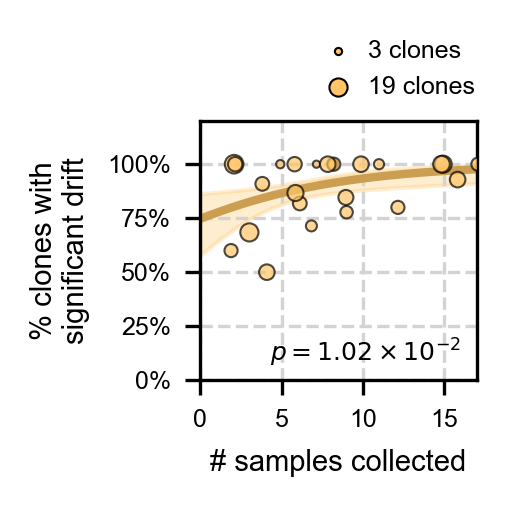

In [15]:
plt.rcParams.update(small_label_settings)
fig, ax = plt.subplots(figsize = (1.7, 1.7), dpi = 300)

label = None
panel(ax, df, 'full_pipeline', label, 0, exp_hue)
ax.set_ylabel('% clones with\nsignificant drift')

sizes = [3, 19]
legend_handles = [
    plt.scatter([], [], s=size, color='#ffc566',
                edgecolors='black', linewidths=0.5)
    for size in sizes
]

leg = ax.legend(legend_handles, [f"{size} clones" for size in sizes],
    frameon=False, loc="lower center", bbox_to_anchor=(0.7, 1.0),
    ncol=1, fontsize=6, handletextpad=0.2
)

plt.tight_layout()

filepath = os.path.join('images', 'lifespan_null.svg')
plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

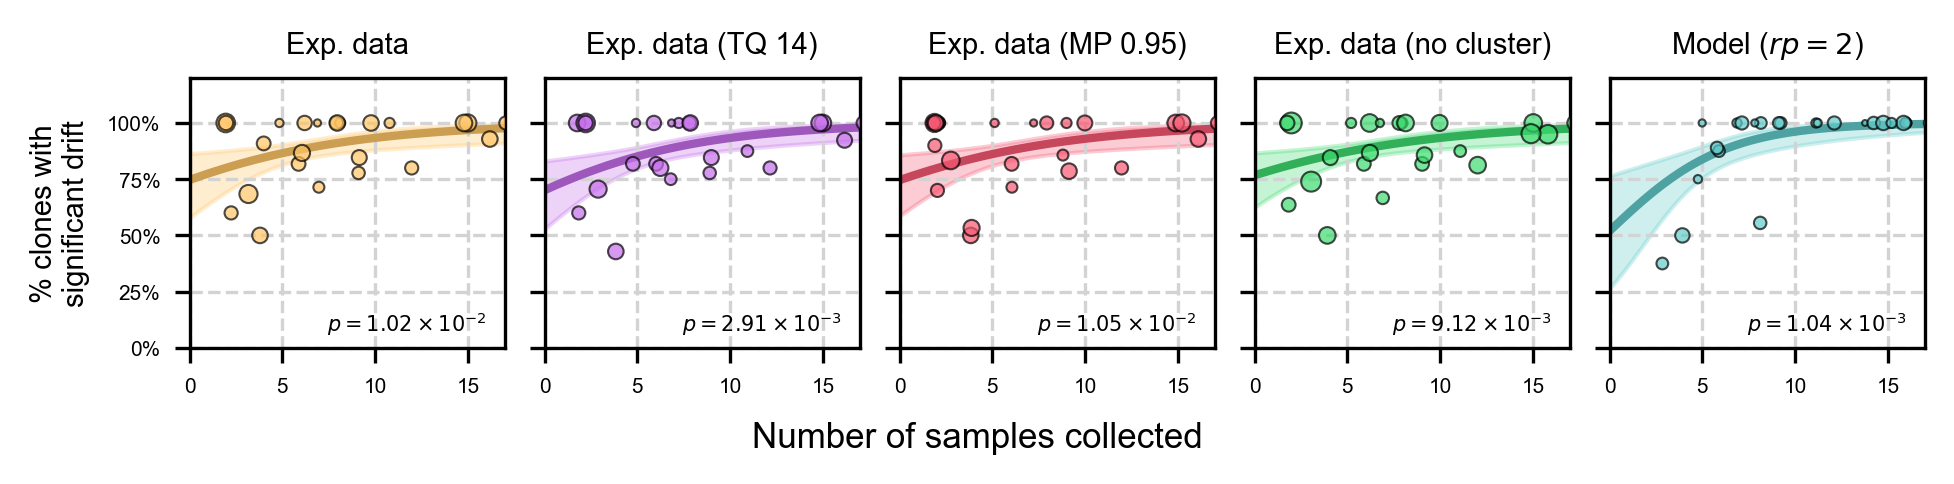

In [8]:
fig, ax = plt.subplots(1, 5, figsize = (6.4, 1.5), dpi = 300, sharey = True, constrained_layout = True)

scenarios = ['full_pipeline', 'full_pipeline_TQ14', 'full_pipeline_MP0.95', 'no_cluster', 'r36_rp2_mimic']
scenarios_labels = ['Exp. data', 'Exp. data (TQ 14)', 'Exp. data (MP 0.95)', 'Exp. data (no cluster)', 'Model ($rp=2$)']
colors = [exp_hue, tq_hue, mp_hue, no_collapse_hue, hue(2)]

for i, (scenario, label, color) in enumerate(zip(scenarios, scenarios_labels, colors)):
    panel(ax[i], df, scenario, label, 0, color)
    ax[i].set_xlabel('')
    
ax[0].set_ylabel('% clones with\nsignificant drift')
fig.supxlabel('Number of samples collected')

# plt.tight_layout()

filepath = os.path.join('images', 'lifespan_null_supplement.svg')
plt.savefig(filepath, pad_inches = 0)

In [15]:
# Re-run the statistical test on additional simulation runs
sim_scenario = 'r36_rp2_mimic'

rows = []
for d in df[df['scenario'] == sim_scenario]['duplicate'].unique():
    model, df2 = logistic_model(df, dep_var, sim_scenario, d)
    
    last_time = model.params[dep_var]
    p = model.pvalues[dep_var]

    row = {'Duplicate': d, 'coef': last_time, 'p': p}
    rows.append(row)

results_df = pd.DataFrame(rows)
results_df

,Duplicate,coef,p
0,0,0.153379,0.018688
1,1,0.299247,0.000133
2,2,0.317731,0.000158
3,3,0.466917,0.000067
4,4,0.331216,0.000080
5,5,0.320973,0.000076
6,6,0.266425,0.004095
7,7,0.302744,0.000160
8,8,0.299267,0.000053
9,9,0.490834,0.000008
